# 第16章 算子优化 Agent 设计

## 本章导读

我们已有检查、计时和接受工具，怎样让程序接着完成下一步？先亲手走一轮，观察“已经测过、尚未判定”的候选，再把重复步骤写成短循环。

默认规划动作由代码预先指定，GPU 评测仍是真实执行。前置：[第15章](../chapter15/chapter15.ipynb)，对照阅读：[本章正文](../../../docs/part3-agent/chapter16/index.md)。


In [ ]:
%run ../../common/bootstrap.py

import json
import pandas as pd
from IPython.display import display
import hello_gpu as gpu
from hello_gpu import agentlab
cfg = gpu.settings()
env = gpu.environment()
env


## 16.1 把系统分成三个部分

规划者提出行动，工具执行检查和测量，工作区保存状态与记录。沿用同一个 kernel；核心计算仍在下面，你可以直接修改。公共桥接层处理文件、进程和展示。


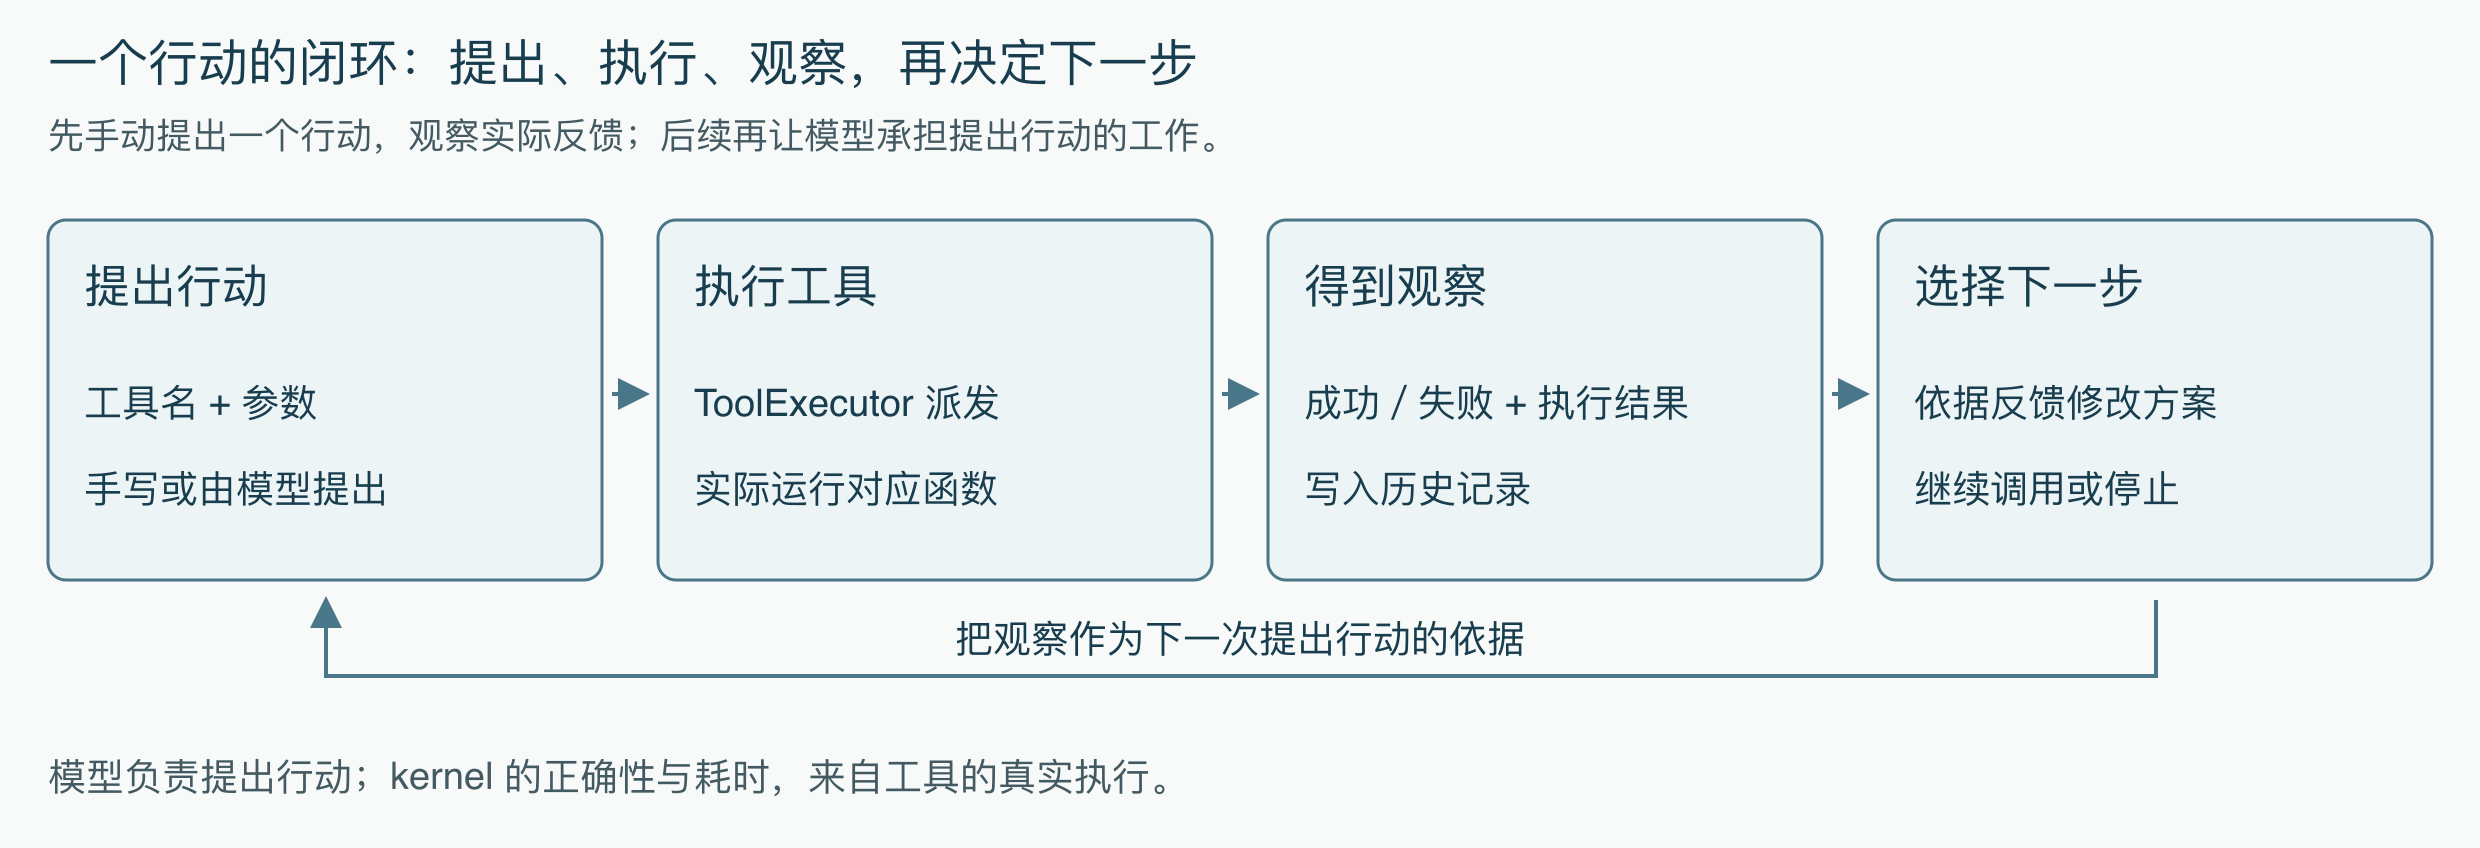

*规划、工具与记录通过实际返回值连接；下一次行动应读取前一步的观察。*


In [ ]:
SOURCE = """import triton
import triton.language as tl

@triton.jit
def add_kernel(x, y, output, n_elements, BLOCK: tl.constexpr):
    offsets = tl.program_id(0) * BLOCK + tl.arange(0, BLOCK)
    valid = offsets < n_elements
    a = tl.load(x + offsets, mask=valid, other=0)
    b = tl.load(y + offsets, mask=valid, other=0)
    result = a + b
    tl.store(output + offsets, result, mask=valid)

def launch(x, y, output, n_elements):
    block_size = 256
    grid = (triton.cdiv(n_elements, block_size),)
    add_kernel[grid](x, y, output, n_elements, BLOCK=block_size,
                     num_warps=4)
"""
SOURCE = SOURCE.replace("block_size = 256", f"block_size = {cfg['block']}")


In [ ]:
lab = agentlab.Lab("chapter16", cfg, baseline_source=SOURCE)
baseline = lab.preflight()
agentlab.show(baseline, title="本轮固定基线")
assert baseline["ok"]


## 16.2 先把问题整理成可检查的任务

执行工具之前，明确它要检查什么。任务记录固定数学语义、调用参数、输入和计时设置；源码记录当前实现。先核对下面的条件，再修改候选。


In [ ]:
display(pd.Series(lab.task_summary()))
assert lab.task["entrypoint"] == "launch"
assert lab.task["launchArguments"] == ["x", "y", "output", "n_elements"]
assert lab.task["tensors"][-1]["value"] == cfg["n"]


## 16.3 让一项假设对应一份候选

候选 A 把 block 扩为两倍，候选 B 扩为四倍。先查看差异。即使两份源码只差一个配置值，它们也必须分别检查，不能把 A 的测量当成 B 的证据。


In [ ]:
source_a = SOURCE.replace(f"block_size = {cfg['block']}",
                          f"block_size = {cfg['block'] * 2}")
source_b = SOURCE.replace(f"block_size = {cfg['block']}",
                          f"block_size = {cfg['block'] * 4}")
agentlab.source_diff(SOURCE, source_a)
agentlab.source_diff(source_a, source_b)


In [ ]:
checked_a = lab.step("compile_kernel", source=source_a)
agentlab.show(checked_a, title="第一步：检查候选 A")
assert checked_a["ok"]
lab.state_view()


## 16.4 管理已经测过、尚未裁决的候选

检查通过后，对 A 计时。此时还没有作出接受决定：程序必须记住哪份源码等待判定，防止测了 A 却把 B 写入当前实现。逐个运行下面的单元格，观察状态变化。


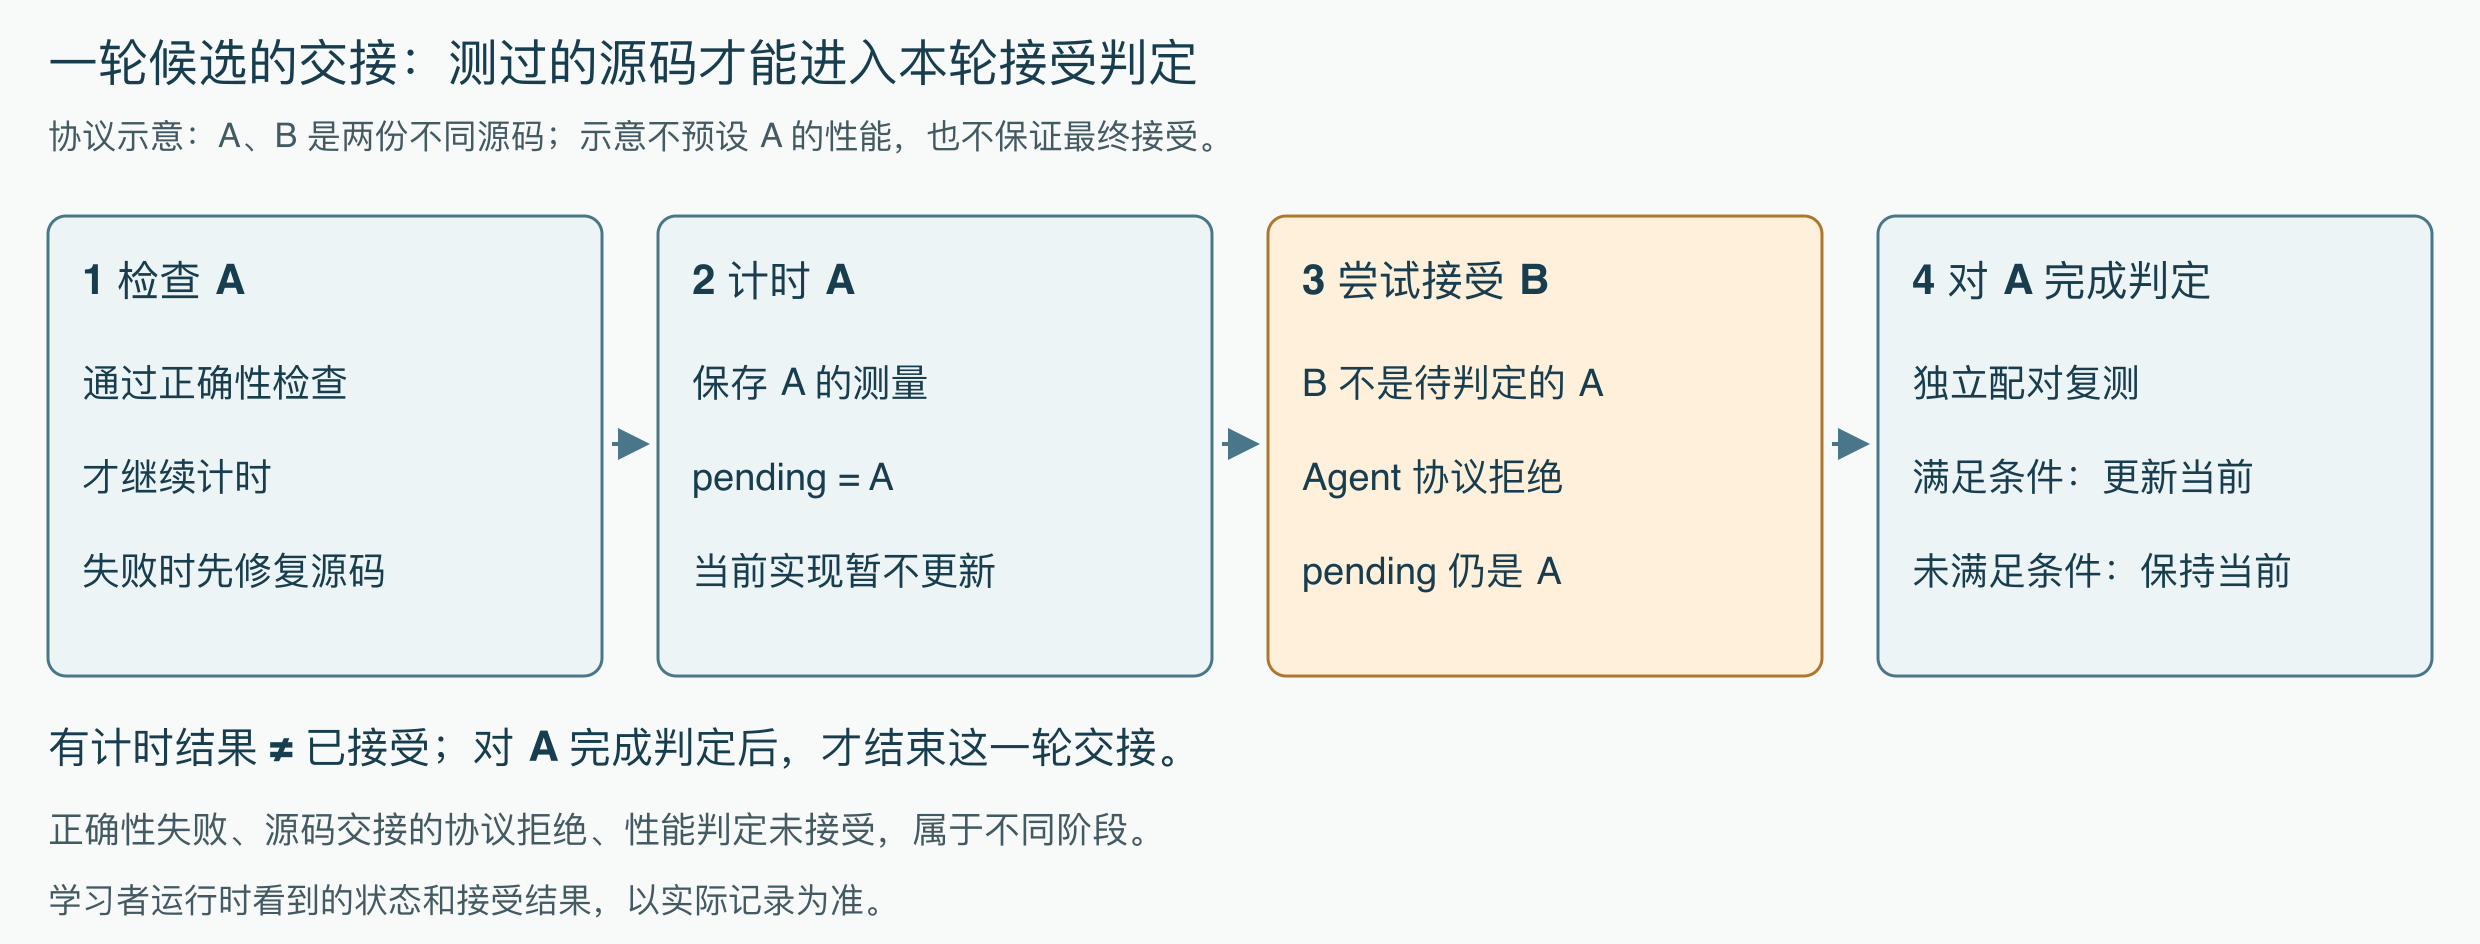

*A 计时后必须对同一份源码完成判定；接受 B 是协议拒绝，性能结果仍需实测。*


In [ ]:
measured_a = lab.step("bench_kernel", source=source_a)
agentlab.show(measured_a, title="第二步：测量候选 A")
assert measured_a["ok"]
_ = lab.sample_plot(measured_a)
lab.state_view()
assert lab.state["pendingCandidate"]


In [ ]:
before = lab.best_path.read_text()
wrong_handoff = lab.step("accept_candidate", source=source_b,
                         change="故意把 A 的交接对象换成 B")
agentlab.show(wrong_handoff, title="第三步：观察换源被拒绝")
assert not wrong_handoff["ok"]
assert lab.best_path.read_text() == before
assert lab.state["pendingCandidate"]
lab.state_view()


**观察**：这是状态协议拒绝，不是“B 太慢”。A 仍等待判定。程序要修复交接对象，不能跳过这一步直接结束或继续替换候选。


In [ ]:
decision_a = lab.step("accept_candidate", source=source_a,
                      change="对同一份候选 A 完成接受判定")
agentlab.show(decision_a, title="第四步：判定候选 A")
_ = lab.pair_plot(decision_a)
assert not lab.state["pendingCandidate"]
lab.state_view()


## 16.5 用反馈调整下一次尝试

现在把重复动作写成循环。`actions` 是可见的预设计划；工具返回值进入 `history`。读懂它之后，才能在第 17 章把“提出行动”交给模型。下面继续尝试 B，每个动作后显示结果。


In [ ]:
actions = [
    ("compile_kernel", {"source": source_b}),
    ("bench_kernel", {"source": source_b}),
    ("accept_candidate", {"source": source_b, "change": "继续检查 block 扩四倍"}),
]
history = []
for name, arguments in actions:
    result = lab.step(name, arguments)
    history.append({"action": name, "observation": result})
    agentlab.show(result, title=f"循环中的动作：{name}")
    lab.state_view()
    if not result.get("ok", False) and name != "accept_candidate":
        break


In [ ]:
display(lab.table())
reflection = "先根据本轮接受理由决定保留或回退，再只修改一个因素。"
print("我的反思：", reflection)
print("仍需证据：资源使用变化不能仅凭时间推断。")


**观察**：循环只是组织执行。真正的反思要读取本轮结果；固定列表不会自行产生新的假设。请修改 `reflection`，引用你刚看到的实际接受理由。


## 16.6 区分停止、完成与加速

停止表示不再继续执行；完成要求没有尚待判定的候选，并留下实际接受判定；加速则还要由独立复测回答。候选被正确拒绝也可以完成一轮优化。


In [ ]:
finished = lab.finish()
lab.state_view()
assert finished["state"] == "complete"
assert not finished["pendingCandidate"]
events = lab.events()
events["阶段"] = events["state"].map(lambda value: value["state"])
display(events[["step", "tool", "bestChanged", "阶段"]])


## 16.7 练习：沿着状态检查程序

故意在计时之后停下，观察为何尚未完成；随后补上同一候选的接受判定。这里的“停止”不代表已获得改善。


In [ ]:
exercise = agentlab.Lab("chapter16-state-exercise", cfg,
                        baseline_source=SOURCE)
exercise_result = exercise.step("bench_kernel", source=source_a)
agentlab.show(exercise_result, title="练习：测量后暂时停止")
assert exercise_result["ok"]
stopped = exercise.finish()
exercise.state_view()
assert stopped["state"] == "incomplete"
assert stopped["pendingCandidate"]


In [ ]:
resolved = exercise.step("accept_candidate", source=source_a,
                         change="补齐同一候选的判定")
agentlab.show(resolved, title="练习：补齐判定")
completed = exercise.finish()
exercise.state_view()
assert completed["state"] == "complete"
assert not completed["pendingCandidate"]


## 本章小结

你已逐步走完检查、计时和判定，看见换源为何被拒绝，并把动作组合成短循环。应能沿着状态解释一次停止是否算完成。下一章运行多轮搜索，再把最终实现固定下来独立复测。


## 延伸阅读

- [本章正文](../../../docs/part3-agent/chapter16/index.md)
- [Triton 向量加法教程](https://triton-lang.org/main/getting-started/tutorials/01-vector-add.html)
- [第17章 notebook](../chapter17/chapter17.ipynb)
